# 1. Percentiles

A percentile is a measure that indicates the value below which a given percentage of observations fall.

The Pth percentile is the value below which P% of the data lies.

For example, the 25th percentile (P25) means 25% of the data is below this value.

Key Percentiles:
* 25th percentile (P25) = Q1 (1st quartile)

* 50th percentile (P50) = Median (Q2)

* 75th percentile (P75) = Q3 (3rd quartile)

1. Always sort the data first.
Percentiles (Q1, Q2, Q3) require data to be in ascending order.

2. Check if the number of elements (n) is odd or even.
This affects how we calculate the median (Q2) and how we split the data for Q1 and Q3.

Even Dataset:
data = [3, 5, 7, 8, 9, 10, 13, 15, 16, 18]

* P25 = 25th percentile = 1st quartile (Q1) = 7

* P50 = Median = 9.5

* P75 = 75th percentile = 3rd quartile (Q3) = 15

Odd data = [3, 5, 7, 8, 9, 10, 13]  # n = 7 (odd)
* Step 1: Median (Q2)
Middle element = data[3] = 8
→ Q2 = 8

* Step 2: Q1 (lower half, exclude median)
Lower half = [3, 5, 7] → middle = 5 → Q1 = 5

* Step 3: Q3 (upper half, exclude median)
Upper half = [9, 10, 13] → middle = 10 → Q3 = 10

Result:

Q1 = 5

Q2 = 8

Q3 = 10

In [1]:
import numpy as np

data = [3, 5, 7, 8, 9, 10, 13, 15, 16, 18]
percentiles = np.percentile(data, [25, 50, 75])
print("Q1 (25th):", percentiles[0])
print("Median (50th):", percentiles[1])
print("Q3 (75th):", percentiles[2])

Q1 (25th): 7.25
Median (50th): 9.5
Q3 (75th): 14.5


#### NumPy uses linear interpolation between ranks for percentiles.
* Rank = (P / 100) * (n - 1)

🔹** What is Interpolation?**

It means estimating a value between two known data points instead of picking one exact data point.

When the exact percentile position doesn’t fall exactly on a data value, we interpolate (take a weighted average) between the two closest values.

For Q1
- Rank = 0.25 * (10 - 1) = 2.25
- So Q1 lies 25% between index 2 and index 3
- data[2] = 7, data[3] = 8
- Q1 = 7 + 0.25*(8-7) = 7.25

For Q2
- Rank = 0.50 * (10 - 1) = 4.5
- Between data[4] = 9 and data[5] = 10
- Q2 = 9 + 0.5*(10 - 9) = 9.5

For Q3
- Q3 = 75th percentile:
- Rank = 0.75 * (10 - 1) = 6.75
- Between data[6] = 13 and data[7] = 15
- Q3 = 13 + 0.75*(15 - 13) = 14.5


In [2]:
# How to match manual method using NumPy?
np.percentile(data, [25, 50, 75], method='nearest') #method='midpoint' or method='nearest'


array([ 7,  9, 15])

In [3]:
import numpy as np

data = [3, 5, 7, 8, 9, 10, 13, 15, 16, 18]

# Classical method: split halves, take medians
Q1_manual = np.median(data[:5])   # lower half
Q2_manual = np.median(data)       # whole dataset
Q3_manual = np.median(data[5:])   # upper half

print("Q1 (manual):", Q1_manual)
print("Q2 (manual, median):", Q2_manual)
print("Q3 (manual):", Q3_manual)


Q1 (manual): 7.0
Q2 (manual, median): 9.5
Q3 (manual): 15.0


# 2. Four Number Summary (boxplot)

A Boxplot (box-and-whisker plot) summarizes a dataset using five numbers, but we often focus on the four-number summary:

Components:
Q1 (25th percentile)

Q2 (50th percentile or median)

Q3 (75th percentile)

IQR (Interquartile Range) = Q3 - Q1

* Outlier Detection (using IQR):
* Lower bound = Q1 - 1.5 × IQR

* Upper bound = Q3 + 1.5 × IQR   
Any values outside this range are considered outliers.

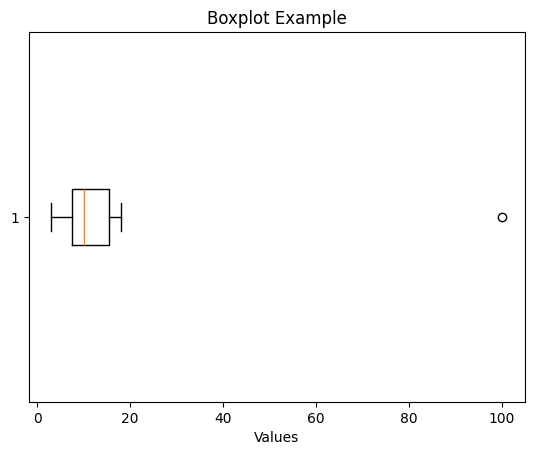

In [4]:
import matplotlib.pyplot as plt

data = [3, 5, 7, 8, 9, 10, 13, 15, 16, 18,100]
plt.boxplot(data, vert=False)
plt.title("Boxplot Example")
plt.xlabel("Values")
plt.show()


This will display:

A box from Q1 to Q3

A line at the median (Q2)

Whiskers extending to min and max within 1.5×IQR

Dots for outliers (if any)

The 1.5 factor is not arbitrary, but it’s based on statistical reasoning:

In a normal distribution, nearly all data (99.7%) lies within:
    
    Q1 − 1.5×IQR to Q3 + 1.5×IQR
Going 1.5 times the IQR beyond Q1 and Q3 captures most non-extreme values, while:

Values below Q1 − 1.5×IQR are considered lower outliers

Values above Q3 + 1.5×IQR are considered upper outliers

This method is resistant to skewness and doesn't assume a normal distribution. It's a good general-purpose rule.

data = [3, 5, 7, 8, 9, 10, 13, 15, 16, 18]

Q1 = 7.25

Q3 = 14.5

IQR = Q3 − Q1 = 7.25

Lower bound = 7.25 − 1.5×7.25 = -3.375

Upper bound = 14.5 + 1.5×7.25 = 25.125


# ** Why 1.5 and not 2 or 3?**

1.5×IQR detects mild outliers

3×IQR is sometimes used to detect extreme outliers

So 1.5 is a balanced threshold that flags unusually far data points without being too aggressive.